# Study 1, notebook 2: the data

The DL3 of the case (simulated with simulst for the mock cases), reduced field by field to map
datasets, and the global statistic of the data,

    Lambda = max over fields of max over the ROI bins b of (TS_b + 2 ln p_b),

where TS_b is the signed Cash TS of the counts correlated over 0.1 deg and the ROI of a field is the GW
95% mask intersected with its observed region (exposure > 0 inside the safe mask).

Inputs: `configs/cases/<CASE>.yaml`; caches `simulst_dl3` (DL3), `reduce` (one per field), `gwmap`.
The simulated cases use the run background model with one normalisation per run fitted to the
counts (`background: fov`).

In [1]:
CASE = "sim_wobble"   # case name in configs/cases/

Imports and figure saver.

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from scipy.stats import norm

from uuls import fields as fl, flux_ul, lambda_stat, realisations, simdata
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("1_flux_ul", "2_data")

Data, fields and the injector of the case, through `flux_ul.prepare` (the same call as the full
limit, so the cache keys are the ones `flux_ul.flux_ul` uses). The first call simulates the runs.

In [3]:
prep = flux_ul.prepare(CASE, verbose=True)
case, flds, sky = prep["case"], prep["fields"], prep["sky"]
print("DL3:", prep["dl3_dir"])
print("background method:", flds[0].reduced.settings["background"])

[cache] simulst_dl3/d0d5331ebbb0: loaded (4 runs)
[cache] gwmap/7a469d1cf166: loaded
[cache] reduce/4543111e282f: loaded


DL3: /data/cta/users-ifae/summer_students/jjimenezq/gw/uncertain-uls/cache/simulst_dl3/d0d5331ebbb0/dl3
background method: fov


What simulst produced, per run.

In [4]:
if case.data_kind == "simulst":
    summ = simdata.run_summary(prep["dl3_dir"])
    summ.pprint(max_lines=25, max_width=140)

obs_id           file               bkg_file     production source ... IRFOFFHI IRFORGHI OFFMAX      LIVETIME            ONTIME      
------ ----------------------- ----------------- ---------- ------ ... -------- -------- ------ ------------------ ------------------
     1 dl3_LST-1.Run00001.fits bkg_Run00001.fits   2025_2p5  False ...      2.6      2.5    2.5 1138.1879999999958 1199.9999999999957
     2 dl3_LST-1.Run00002.fits bkg_Run00002.fits   2025_2p5  False ...      2.6      2.5    2.5 1138.1879999999958 1200.0000000000052
     3 dl3_LST-1.Run00003.fits bkg_Run00003.fits   2025_2p5  False ...      2.6      2.5    2.5  1140.571199999996 1200.0000000000052
     4 dl3_LST-1.Run00004.fits bkg_Run00004.fits   2025_2p5  False ...      2.6      2.5    2.5 1140.5507999999957 1199.9999999999957


Per field: runs, counts and background summed over the ROI and over energy, excess, and the GW
probability of the ROI (binned on the field's grid).

In [5]:
pres = realisations.precompute_fields(flds)
rows = []
for f, pre in zip(flds, pres):
    ds = f.reduced.stacked
    roi = pre.mask
    n = ds.counts.data.sum(axis=0)[roi].sum()
    b = ds.background.data.sum(axis=0)[roi].sum()
    rows.append((f.name, len(f.obs_ids), int(roi.sum()), n, b, n - b, (n - b) / np.sqrt(b) if b > 0 else np.nan,
                 f.gwmap.prob[roi].sum()))
info = Table(rows=rows, names=("field", "runs", "roi_bins", "counts", "background", "excess",
                               "excess_sigma", "gw_prob_roi"))
for c in ("background", "excess", "excess_sigma"):
    info[c].format = ".1f"
info["gw_prob_roi"].format = ".4f"
info.pprint(max_lines=40)

field  runs roi_bins counts background excess excess_sigma gw_prob_roi
------ ---- -------- ------ ---------- ------ ------------ -----------
field0    4     1033 2873.0     2903.8  -30.8         -0.6      0.9486


Maps of the field holding the maximum of Lambda: counts and background summed over energy,
exposure summed over true energy, and the significance sign(TS) sqrt(|TS|) of the correlated counts.
The white contour is the ROI, the cross the bin of the observed Lambda.

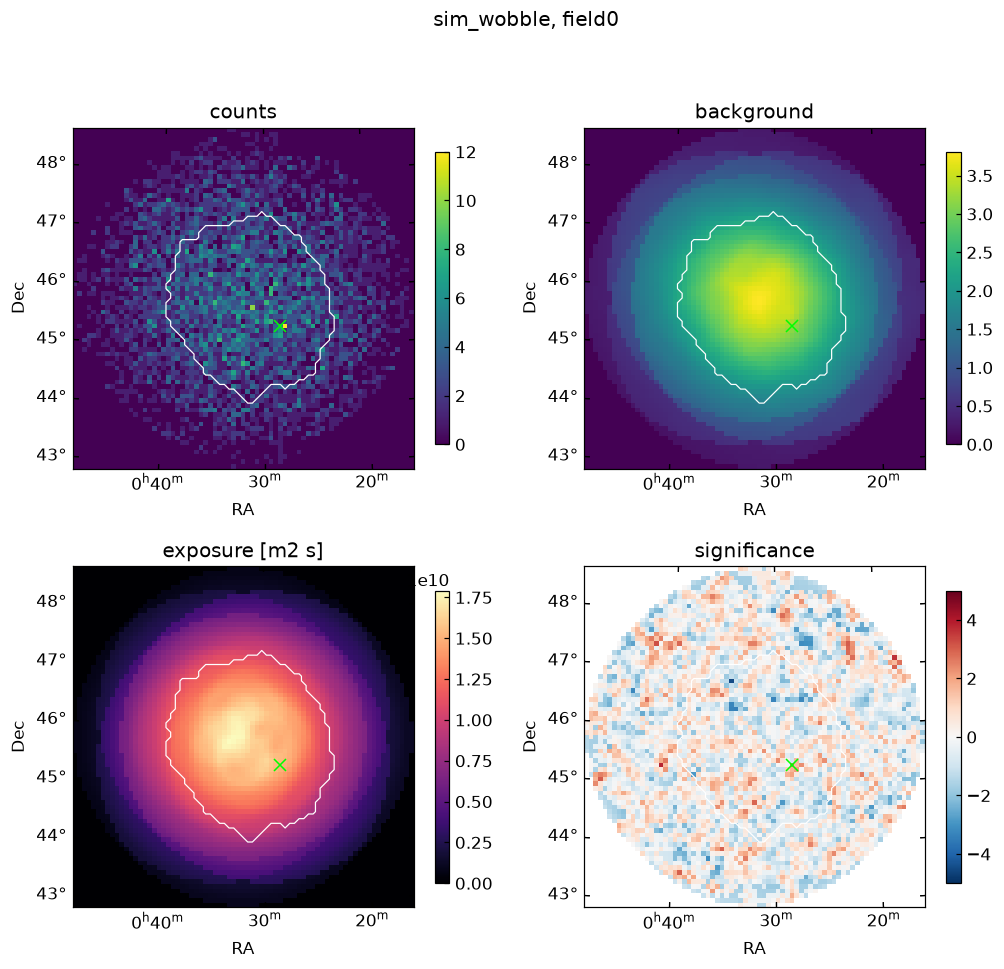

In [6]:
obs = fl.observed_lambda(flds)
k = obs["field"]
f, pre = flds[k], pres[k]
ds = f.reduced.stacked
ts = pre.ts(ds.counts.data)
sig = np.sign(ts) * np.sqrt(np.abs(ts))
expo = ds.exposure.data.sum(axis=0)
panels = [("counts", ds.counts.data.sum(axis=0), "viridis", {}),
          ("background", ds.background.data.sum(axis=0), "viridis", {}),
          ("exposure [m2 s]", expo, "magma", {}),
          ("significance", np.where(expo > 0, sig, np.nan), "RdBu_r", {"vmin": -5, "vmax": 5})]
fig = plt.figure(figsize=(11, 9.5))
for j, (title, img, cmap, kw) in enumerate(panels):
    ax = fig.add_subplot(2, 2, j + 1, projection=f.geom.to_image().wcs)
    im = ax.imshow(img, origin="lower", cmap=cmap, **kw)
    ax.contour(pre.mask.astype(float), levels=[0.5], colors="w", linewidths=0.8)
    ax.plot(obs["lambda_ix"], obs["lambda_iy"], "x", color="lime", ms=8)
    ax.set_title(title)
    ax.set_xlabel("RA")
    ax.set_ylabel("Dec")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"{case.name}, {f.name}")
figs.save(fig, "maps")
plt.show()

Significance of every ROI bin of every field. With no source the distribution should be close to a
unit normal; the correlation over 0.1 deg makes neighbouring bins dependent but does not change the
one-bin distribution.

1033 ROI bins: mean -0.073, std 1.020, max 2.90


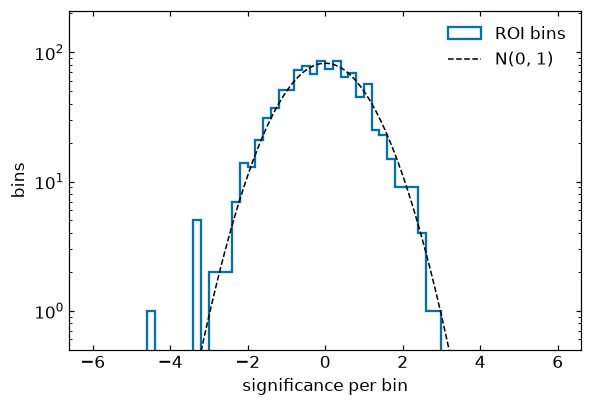

In [7]:
s_all = []
for f_, p_ in zip(flds, pres):
    t_ = p_.ts(f_.reduced.stacked.counts.data)
    s_all.append((np.sign(t_) * np.sqrt(np.abs(t_)))[p_.mask])
s_all = np.concatenate(s_all)
print(f"{s_all.size} ROI bins: mean {s_all.mean():.3f}, std {s_all.std():.3f}, max {s_all.max():.2f}")
fig, ax = plt.subplots(figsize=(6, 4))
bins = np.linspace(-6, 6, 61)
ax.hist(s_all, bins=bins, histtype="step", lw=1.5, label="ROI bins")
x = np.linspace(-6, 6, 300)
ax.plot(x, s_all.size * (bins[1] - bins[0]) * norm.pdf(x), "k--", lw=1, label="N(0, 1)")
ax.set_yscale("log")
ax.set_ylim(0.5, None)
ax.set_xlabel("significance per bin")
ax.set_ylabel("bins")
ax.legend()
figs.save(fig, "significance_distribution")
plt.show()

## Observed Lambda

The maximum over fields of TS_b + 2 ln p_b in the ROI, where it is reached, and the two terms there.
The maximum TS in the ROI is printed for comparison: Lambda need not sit on the TS maximum, since the
GW probability term pulls it towards the dense part of the map.

In [8]:
iy, ix = obs["lambda_iy"], obs["lambda_ix"]
pos = f.geom.to_image().pix_to_coord((ix, iy))
two_ln_p = lambda_stat.log_prob_term(f.gwmap.prob)[iy, ix]
print(f"Lambda_obs = {obs['lambda']:.3f} in {f.name} at RA {np.squeeze(pos[0].to_value('deg')):.3f}, Dec {np.squeeze(pos[1].to_value('deg')):.3f} deg")
print(f"  TS there {ts[iy, ix]:.3f}, 2 ln p there {two_ln_p:.3f}; max TS in the ROI {obs['tsmax']:.3f}")
if len(flds) > 1:
    print("Lambda per field:", np.round(obs["lambda_fields"], 2))
print(f"GW probability of the ROI (HEALPix, overlaps once): {flux_ul.roi_gw_prob(flds, sky):.4f}")

Lambda_obs = -5.456 in field0 at RA 7.099, Dec 45.300 deg
  TS there 7.178, 2 ln p there -12.634; max TS in the ROI 8.416
GW probability of the ROI (HEALPix, overlaps once): 0.9475


## Outputs

Figures in `outputs/figures/1_flux_ul/2_data/`: `maps`, `significance_distribution`. The DL3 and the
reduced datasets are in the cache (`simulst_dl3`, `reduce`); notebook 3 reuses them.